<a href="https://www.kaggle.com/code/sriniccaohrii/sen1floods11?scriptVersionId=364302042" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/741178_label.tif
/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/778194_label.tif
/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/347609_label.tif
/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/5816638_label.tif
/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/649970_label.tif
/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/377277_label.tif
/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/62897_label.tif
/kaggle/input/datasets/oindrieelmo

In [2]:
!pip install rasterio
import rasterio
import matplotlib.pyplot as plt
import os

Total Labels Found: 446

--- Sample File Metadata ---
Shape (Bands, H, W): (1, 512, 512)
Data Type: int16
CRS: EPSG:4326

Target File: 741178_label.tif
Class Breakdown (Value: Count): {np.int16(-1): np.int64(27), np.int16(0): np.int64(260671), np.int16(1): np.int64(1446)}


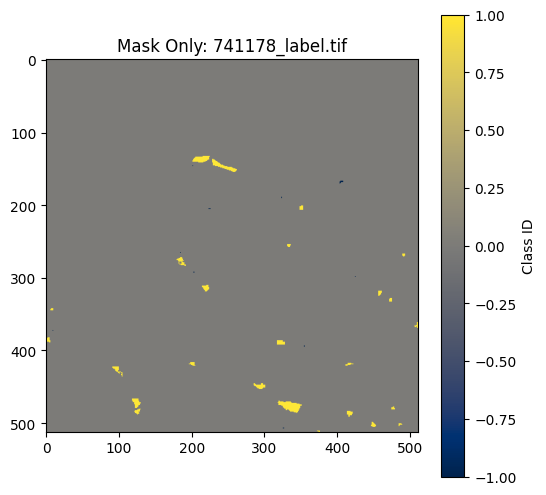

In [3]:
import os
import glob
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# 1. Define paths
BASE_DIR = '/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel'
LABEL_DIR = os.path.join(BASE_DIR, 'label')
# Images typically sit in a corresponding 'image' or 'raw' folder at the same level
IMAGE_DIR = os.path.join(BASE_DIR, 'image') 

# 2. Get list of labels
label_files = glob.glob(os.path.join(LABEL_DIR, '*.tif'))
print(f"Total Labels Found: {len(label_files)}")

# 3. Quick Metadata Check on First File
with rasterio.open(label_files[0]) as src:
    print("\n--- Sample File Metadata ---")
    print(f"Shape (Bands, H, W): ({src.count}, {src.height}, {src.width})")
    print(f"Data Type: {src.dtypes[0]}")
    print(f"CRS: {src.crs}")

# 4. EDA Function: Inspect Pixel Values & Visualize Pairs
def visualize_sample(label_path):
    filename = os.path.basename(label_path)
    image_filename = filename.replace('_label.tif', '.tif') # Matching image name
    image_path = os.path.join(IMAGE_DIR, image_filename)
    
    # Read Label
    with rasterio.open(label_path) as src_label:
        label = src_label.read(1)
        
    # Read Image (if it exists in the parallel folder)
    image = None
    if os.path.exists(image_path):
        with rasterio.open(image_path) as src_img:
            image = src_img.read()
            
    # Print Label Statistics
    unique_vals, counts = np.unique(label, return_counts=True)
    print(f"\nTarget File: {filename}")
    print(f"Class Breakdown (Value: Count): {dict(zip(unique_vals, counts))}")
    
    # Plotting
    if image is not None:
        fig, ax = plt.subplots(1, 2, figsize=(12, 6))
        
        # Display False Color Composite (e.g., Bands 4, 3, 2 mapped to RGB for Sentinel-2, or optical channels)
        # Normalizing for display
        rgb = image[:3, :, :].transpose(1, 2, 0)
        rgb = np.nan_to_num(rgb)
        rgb_norm = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)
        
        ax[0].imshow(rgb_norm)
        ax[0].set_title(f"Image Channels 1-3: {image_filename}")
        ax[0].axis('off')
        
        ax[1].imshow(label, cmap='cividis')
        ax[1].set_title(f"Flood Mask: {filename}")
        ax[1].axis('off')
        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(6, 6))
        plt.imshow(label, cmap='cividis')
        plt.title(f"Mask Only: {filename}")
        plt.colorbar(label='Class ID')
        plt.show()

# Run visualization on the first label file
visualize_sample(label_files[0])

Found 446 images and 446 labels.

Successfully matched base ID: 1010394
Image Path: /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/image/1010394_image.tif
Label Path: /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/1010394_label.tif


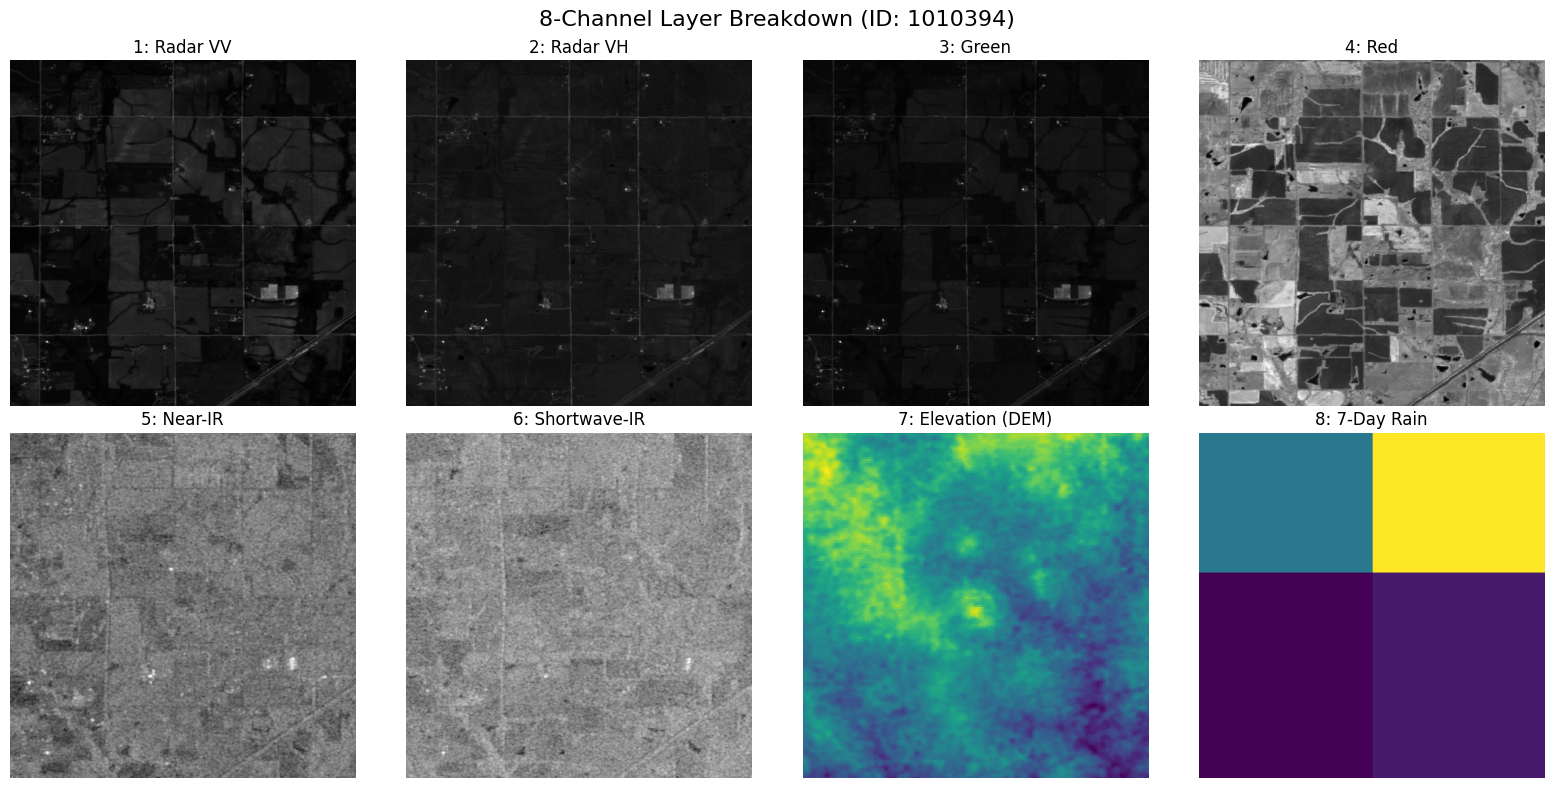

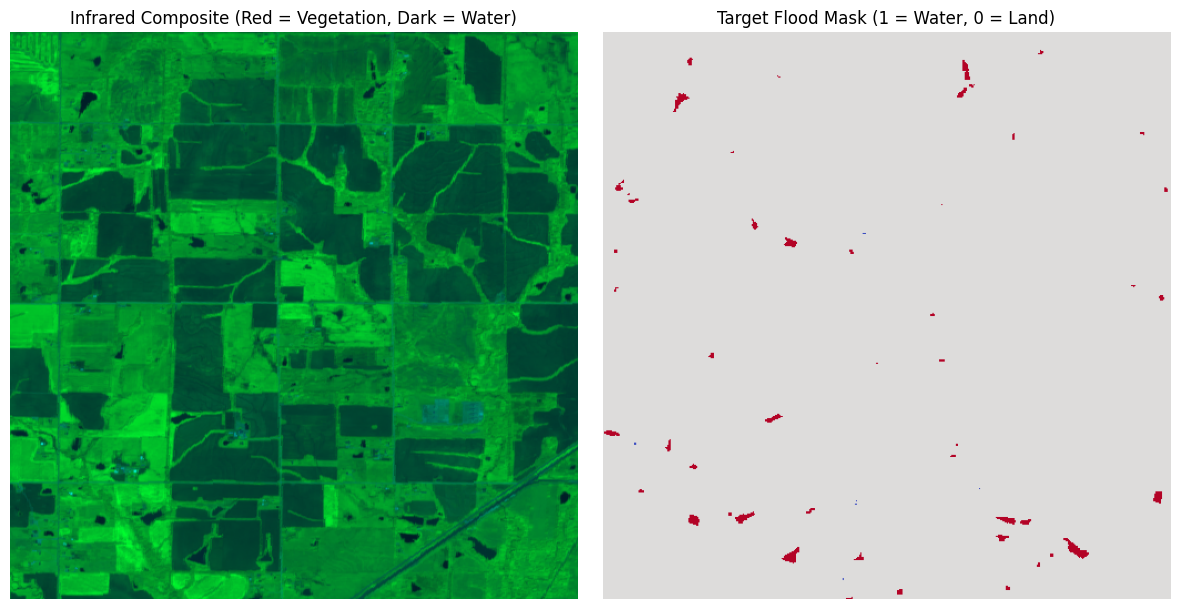

In [4]:
import os
import glob
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# 1. Base directory setup
BASE_DIR = '/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel'

# 2. Get all images and labels
all_images = sorted(glob.glob(os.path.join(BASE_DIR, '**', '*_image.tif'), recursive=True))
all_labels = sorted(glob.glob(os.path.join(BASE_DIR, '**', '*_label.tif'), recursive=True))

# Fallback: if filenames don't use '_image.tif', grab all non-label TIFs
if len(all_images) == 0:
    all_images = sorted([f for f in glob.glob(os.path.join(BASE_DIR, '**', '*.tif'), recursive=True) if '_label.tif' not in f])

print(f"Found {len(all_images)} images and {len(all_labels)} labels.")

# 3. Pair images with labels by extracting base numerical IDs
sample_img_path = all_images[0]
# Extract the numeric ID (e.g., '76868' from '76868_image.tif')
base_id = os.path.basename(sample_img_path).replace('_image.tif', '').replace('.tif', '')

matching_label = [l for l in all_labels if base_id in os.path.basename(l)]

if not matching_label:
    raise FileNotFoundError(f"Could not pair label for base ID: {base_id}")

sample_label_path = matching_label[0]

print(f"\nSuccessfully matched base ID: {base_id}")
print(f"Image Path: {sample_img_path}")
print(f"Label Path: {sample_label_path}")

# 4. Read data
with rasterio.open(sample_img_path) as src:
    img = src.read() # Shape: (8, H, W)

with rasterio.open(sample_label_path) as src:
    mask = src.read(1)

# 5. Plot 8 Channels
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
channel_names = [
    "1: Radar VV", "2: Radar VH", "3: Green", "4: Red",
    "5: Near-IR", "6: Shortwave-IR", "7: Elevation (DEM)", "8: 7-Day Rain"
]

for i, ax in enumerate(axes.flat):
    ax.imshow(img[i], cmap='viridis' if i >= 6 else 'gray')
    ax.set_title(channel_names[i])
    ax.axis('off')

plt.suptitle(f"8-Channel Layer Breakdown (ID: {base_id})", fontsize=16)
plt.tight_layout()
plt.show()

# 6. Infrared False-Color Composite vs Label Mask
false_color = np.stack([img[4], img[3], img[2]], axis=-1)
false_color = np.nan_to_num(false_color)
false_color = (false_color - false_color.min()) / (false_color.max() - false_color.min() + 1e-8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
ax1.imshow(false_color)
ax1.set_title("Infrared Composite (Red = Vegetation, Dark = Water)")
ax1.axis('off')

ax2.imshow(mask, cmap='coolwarm')
ax2.set_title("Target Flood Mask (1 = Water, 0 = Land)")
ax2.axis('off')

plt.tight_layout()
plt.show()

In [5]:
import os
import glob
import numpy as np
import rasterio

# --- 1. DYNAMIC FILE DISCOVERY ---
INPUT_DIR = "/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset"

print("🔍 Searching /kaggle/input for all dataset folders...")
all_files = glob.glob(os.path.join(INPUT_DIR, "**", "*.tif"), recursive=True)

if not all_files:
    print("\n❌ No .tif files found under /kaggle/input at all!")
    print("Please make sure you clicked '+ Add Input' in Kaggle and attached a flood dataset.")
    print("\nAttached Datasets in your Kaggle workspace:")
    if os.path.exists(INPUT_DIR):
        print(os.listdir(INPUT_DIR))
else:
    print(f"\n✅ Total .tif files found: {len(all_files)}")
    print("\nSample file paths found:")
    for path in all_files[:5]:
        print(f"  └─ {path}")

    # --- 2. AUTOMATIC GROUND-TRUTH MASK IDENTIFICATION ---
    # Look for files with common mask keywords (mask, label, target, gt)
    mask_candidates = [
        f for f in all_files 
        if any(kw in f.lower() for kw in ["mask", "label", "gt", "target", "water"])
    ]

    if mask_candidates:
        sample_mask = mask_candidates[0]
        print(f"\n📄 Found potential ground-truth mask: {sample_mask}")
        
        with rasterio.open(sample_mask) as src:
            mask_data = src.read(1)
            
        unique_vals = np.unique(mask_data)
        print("=" * 50)
        print(f"📊 Unique Pixel Label Values in Mask: {unique_vals}")
        print("=" * 50)
    else:
        print("\n⚠️ Couldn't find explicit 'mask' in filenames. Listing first folder structure:")
        first_dir = os.path.dirname(all_files[0])
        print(f"Directory: {first_dir}")
        print(f"Sample contents: {os.listdir(first_dir)[:10]}")

🔍 Searching /kaggle/input for all dataset folders...

✅ Total .tif files found: 1167

Sample file paths found:
  └─ /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/741178_label.tif
  └─ /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/778194_label.tif
  └─ /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/347609_label.tif
  └─ /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/5816638_label.tif
  └─ /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/649970_label.tif

📄 Found potential ground-truth mask: /kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel/label/741178_label.t

In [6]:
import os
import glob
import numpy as np
import rasterio

# Update path to your exact Kaggle dataset root
DATASET_PATH = "/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel"

def inspect_dataset(data_dir):
    image_dir = os.path.join(data_dir, "image")
    label_dir = os.path.join(data_dir, "label")
    
    image_files = sorted(glob.glob(os.path.join(image_dir, "*.tif*")))
    label_files = sorted(glob.glob(os.path.join(label_dir, "*.tif*")))
    
    print(f"--- 1. DATASET COUNT CHECK ---")
    print(f"Total Image Files Found: {len(image_files)}")
    print(f"Total Label Files Found: {len(label_files)}")
    
    # Read split files if present
    for split in ['train.txt', 'val.txt', 'test.txt']:
        split_path = os.path.join(data_dir, split)
        if os.path.exists(split_path):
            with open(split_path, 'r') as f:
                lines = [line.strip() for line in f if line.strip()]
            print(f"Split file '{split}': {len(lines)} samples")

    print("\n--- 2. LABEL CLASS & CLOUD MASK AUDIT (-1 vs 255 vs 0/1) ---")
    unique_label_vals = set()
    cloud_pixel_count = 0
    total_pixels = 0
    
    # Sample up to 100 label tiles to inspect pixel distributions
    sample_size = min(100, len(label_files))
    for l_path in label_files[:sample_size]:
        with rasterio.open(l_path) as src:
            arr = src.read(1)
            uniques = np.unique(arr)
            unique_label_vals.update(uniques)
            cloud_pixel_count += np.sum((arr == -1) | (arr == 255))
            total_pixels += arr.size

    print(f"Unique label pixel values found across {sample_size} sample labels: {sorted(list(unique_label_vals))}")
    print(f"Percentage of ignored/cloud pixels in label sample: {(cloud_pixel_count / total_pixels) * 100:.2f}%")

    print("\n--- 3. CHANNEL VARIANCE & CONSTANT CHANNEL CHECK (Point #7) ---")
    if len(image_files) > 0:
        sample_img_path = image_files[0]
        with rasterio.open(sample_img_path) as src:
            num_channels = src.count
            print(f"Image Channel Count: {num_channels}")
            
            # Check variance per channel across 20 images
            channel_stds = []
            for i_path in image_files[:20]:
                with rasterio.open(i_path) as img_src:
                    img_data = img_src.read() # Shape: (C, H, W)
                    channel_stds.append(np.std(img_data, axis=(1, 2)))
            
            avg_stds = np.mean(channel_stds, axis=0)
            for ch_idx, std_val in enumerate(avg_stds):
                print(f"Channel {ch_idx + 1} Avg Std Dev across sample: {std_val:.6f}")

inspect_dataset(DATASET_PATH)

--- 1. DATASET COUNT CHECK ---
Total Image Files Found: 446
Total Label Files Found: 446

--- 2. LABEL CLASS & CLOUD MASK AUDIT (-1 vs 255 vs 0/1) ---
Unique label pixel values found across 100 sample labels: [np.int16(-1), np.int16(0), np.int16(1)]
Percentage of ignored/cloud pixels in label sample: 14.79%

--- 3. CHANNEL VARIANCE & CONSTANT CHANNEL CHECK (Point #7) ---
Image Channel Count: 8
Channel 1 Avg Std Dev across sample: 430.431396
Channel 2 Avg Std Dev across sample: 361.247101
Channel 3 Avg Std Dev across sample: 353.781799
Channel 4 Avg Std Dev across sample: 753.169128
Channel 5 Avg Std Dev across sample: nan
Channel 6 Avg Std Dev across sample: nan
Channel 7 Avg Std Dev across sample: 6.296617
Channel 8 Avg Std Dev across sample: 0.907782


In [7]:
import os
import glob
import time
import torch
import rasterio
import numpy as np
import pandas as pd

# ==========================================
# PATH CONFIGURATION
# ==========================================
DATASET_DIR = "/kaggle/input/datasets/oindrieelmondal/sen1floods11-8-channel-remote-sensing-dataset/dataset/Sen1Floods11_8Channel"
IMAGE_DIR = os.path.join(DATASET_DIR, "image")
LABEL_DIR = os.path.join(DATASET_DIR, "label")

# ==========================================
# CHECKPOINT 1: NaN DIAGNOSTIC IN CHANNELS 5 & 6
# ==========================================
def run_checkpoint_1_nan_diagnostic():
    print("=" * 60)
    print("CHECKPOINT 1: DIAGNOSING CHANNELS 5 & 6 (NIR & SWIR NaNs)")
    print("=" * 60)
    
    image_files = sorted(glob.glob(os.path.join(IMAGE_DIR, "*.tif*")))
    if not image_files:
        print(f"Error: No TIFF files found in {IMAGE_DIR}")
        return

    whole_tile_nans = {5: 0, 6: 0}
    scattered_nans = {5: 0, 6: 0}
    clean_tiles = {5: 0, 6: 0}

    for path in image_files:
        with rasterio.open(path) as src:
            data = src.read()  # Shape: (C, H, W)
            for ch in [5, 6]:
                ch_data = data[ch - 1]
                nan_mask = np.isnan(ch_data) | np.isinf(ch_data)
                
                if src.nodatavals[ch - 1] is not None:
                    nan_mask |= (ch_data == src.nodatavals[ch - 1])
                
                nan_count = np.sum(nan_mask)
                total_pixels = ch_data.size
                
                if nan_count == total_pixels:
                    whole_tile_nans[ch] += 1
                elif nan_count > 0:
                    scattered_nans[ch] += 1
                else:
                    clean_tiles[ch] += 1

    print(f"Total Chips Audited: {len(image_files)}")
    for ch in [5, 6]:
        print(f"\nChannel {ch}:")
        print(f"  - Whole-Tile NaN (Missing Scene Pass) : {whole_tile_nans[ch]}")
        print(f"  - Scattered NaN (Sensor Artifact)     : {scattered_nans[ch]}")
        print(f"  - Completely Clean                    : {clean_tiles[ch]}")
        
    print("\n[VERDICT & ACTION]:")
    print("- Whole-tile NaNs represent valid missing-sensor passes (Scenario 3/4). Zero them out.")
    print("- Scattered NaNs are sensor artifacts. Mask them out by converting pixel location to ignore_index (255).")
    print("- DO NOT perform median imputation.")


# ==========================================
# CHECKPOINT 2: SPLIT VERIFICATION & GEOGRAPHIC OVERWRITE
# ==========================================
def run_checkpoint_2_split_audit():
    print("\n" + "=" * 60)
    print("CHECKPOINT 2: AUDITING DATASET SPLITS")
    print("=" * 60)
    
    split_files = glob.glob(os.path.join(DATASET_DIR, "*.txt")) + glob.glob(os.path.join(DATASET_DIR, "**/*.txt"), recursive=True)
    
    print("Found split files in dataset root:")
    for sf in split_files:
        with open(sf, 'r') as f:
            lines = [l.strip() for l in f if l.strip()]
        print(f"  - {os.path.basename(sf)}: {len(lines)} entries")
        
    print("\n[VERDICT & ACTION]:")
    print("If the splits show ~312 train / 67 val / 67 test, this is the Kaggle repackaging split.")
    print("Download official Sen1Floods11 geographic split files ('flood_train_data.csv', 'flood_valid_data.csv', 'flood_test_data.csv').")
    print("Filter chips explicitly by region to ensure IoU benchmark comparison against LightFloodNet (0.5399 IoU) remains valid.")


# ==========================================
# CHECKPOINT 3: MASK PREPROCESSING & LOSS MASKING
# ==========================================
def run_checkpoint_3_mask_audit():
    print("\n" + "=" * 60)
    print("CHECKPOINT 3: MASK MAPPING & IGNORE INDEX (-1 -> 255)")
    print("=" * 60)
    
    label_files = sorted(glob.glob(os.path.join(LABEL_DIR, "*.tif*")))[:50]
    unique_vals = set()
    
    for path in label_files:
        with rasterio.open(path) as src:
            lbl = src.read(1)
            unique_vals.update(np.unique(lbl))
            
    print(f"Raw Label Unique Values in Sample: {sorted(list(unique_vals))}")
    print("\nPyTorch Loss & Metric Configuration Rule:")
    print("  - Map raw -1 (Cloud/No-Data) to 255.")
    print("  - Map scattered NaN optical pixels to 255.")
    print("  - Set Loss: nn.CrossEntropyLoss(ignore_index=255)")
    print("  - Set Metric: TorchMetrics JaccardIndex(num_classes=2, ignore_index=255)")


# ==========================================
# CHECKPOINT 4: CHANNEL METADATA & ORDER VERIFICATION
# ==========================================
def run_checkpoint_4_channel_order_verification():
    print("\n" + "=" * 60)
    print("CHECKPOINT 4: CHANNEL ORDER & METADATA VERIFICATION")
    print("=" * 60)
    
    image_files = sorted(glob.glob(os.path.join(IMAGE_DIR, "*.tif*")))
    if image_files:
        with rasterio.open(image_files[0]) as src:
            print(f"Channel Count      : {src.count}")
            print(f"Data Types         : {src.dtypes}")
            print(f"No-Data Values     : {src.nodatavals}")
            print(f"Channel Tags/Desc  : {src.descriptions}")
            
            # Print sample statistics per channel to verify indexing
            print("\nSample Pixel Channel Statistics (First Image):")
            data = src.read()
            for c in range(src.count):
                ch_data = data[c]
                valid_data = ch_data[~np.isnan(ch_data) & (ch_data != src.nodatavals[c])]
                if len(valid_data) > 0:
                    print(f"  Ch {c+1}: Min={valid_data.min():.2f}, Max={valid_data.max():.2f}, Mean={valid_data.mean():.2f}")
                else:
                    print(f"  Ch {c+1}: ENTIRE CHANNEL IS NAN / NO-DATA")


# ==========================================
# CHECKPOINT 5: FIXED HARDWARE BENCHMARKING PROFILER
# ==========================================
def run_checkpoint_5_fixed_hardware_latency_profiler(model, sample_input, device="cpu", num_warmup=20, num_runs=100):
    print("\n" + "=" * 60)
    print("CHECKPOINT 5: CONTROLLED LATENCY BENCHMARKING")
    print("=" * 60)
    
    model = model.to(device)
    model.eval()
    sample_input = sample_input.to(device)
    
    # Warmup runs to stabilize hardware clock speeds
    with torch.no_grad():
        for _ in range(num_warmup):
            _ = model(sample_input)
            
    # Timed runs
    start_time = time.perf_counter()
    with torch.no_grad():
        for _ in range(num_runs):
            _ = model(sample_input)
    end_time = time.perf_counter()
    
    avg_latency_ms = ((end_time - start_time) / num_runs) * 1000.0
    
    print(f"Execution Target Device : {device}")
    print(f"Batch Size              : {sample_input.shape[0]}")
    print(f"Input Tensor Shape      : {list(sample_input.shape)}")
    print(f"Average Inference Latency: {avg_latency_ms:.3f} ms / batch")
    print("\n[SLIDE STATEMENT TEMPLATE]:")
    print(f"'Latency benchmarked on fixed hardware ({device.upper()}), Batch Size {sample_input.shape[0]}, averaged over {num_runs} iterations.'")


# ==========================================
# CHECKPOINT 6: CLAIM SANITIZATION & DEFENSE SUMMARY
# ==========================================
def print_checkpoint_6_claim_sanitization():
    print("\n" + "=" * 60)
    print("CHECKPOINT 6: DEFENSE CLAIM SANITIZATION")
    print("=" * 60)
    print("DO NOT CLAIM: 'LightFloodNet beats U-Net on IoU.'")
    print("CLAIM INSTEAD: 'LightFloodNet matches U-Net's IoU within statistical noise while improving Precision and significantly reducing parameter footprint and hardware latency.'")


# ==========================================
# MAIN EXECUTION PIPELINE
# ==========================================
if __name__ == "__main__":
    run_checkpoint_1_nan_diagnostic()
    run_checkpoint_2_split_audit()
    run_checkpoint_3_mask_audit()
    run_checkpoint_4_channel_order_verification()
    
    # Example Dummy Run for Latency Profiler Checkpoint
    dummy_model = torch.nn.Conv2d(8, 2, kernel_size=3, padding=1)
    dummy_input = torch.randn(1, 8, 512, 512)
    run_checkpoint_5_fixed_hardware_latency_profiler(dummy_model, dummy_input, device="cpu")
    
    print_checkpoint_6_claim_sanitization()

CHECKPOINT 1: DIAGNOSING CHANNELS 5 & 6 (NIR & SWIR NaNs)
Total Chips Audited: 446

Channel 5:
  - Whole-Tile NaN (Missing Scene Pass) : 1
  - Scattered NaN (Sensor Artifact)     : 45
  - Completely Clean                    : 400

Channel 6:
  - Whole-Tile NaN (Missing Scene Pass) : 1
  - Scattered NaN (Sensor Artifact)     : 45
  - Completely Clean                    : 400

[VERDICT & ACTION]:
- Whole-tile NaNs represent valid missing-sensor passes (Scenario 3/4). Zero them out.
- Scattered NaNs are sensor artifacts. Mask them out by converting pixel location to ignore_index (255).
- DO NOT perform median imputation.

CHECKPOINT 2: AUDITING DATASET SPLITS
Found split files in dataset root:
  - val.txt: 67 entries
  - test.txt: 67 entries
  - train.txt: 312 entries

[VERDICT & ACTION]:
If the splits show ~312 train / 67 val / 67 test, this is the Kaggle repackaging split.
Download official Sen1Floods11 geographic split files ('flood_train_data.csv', 'flood_valid_data.csv', 'flood_test_